# OSSE GLORYS12 along-track — satellite footprint (Dec 2023 → Jan 2025)

Build **two** OSSE along-track `.nc` files by sampling gap-free **GLORYS12 SLA (truth)** at the
**real satellite footprint** (time, lat, lon) of the OSE test period:

- **`..._wo_Altika.nc`** — footprint = *7 nadirs (NO SARAL/AltiKa) + SWOT KARIN*
  (already combined in `alongtrack_S7nadirsNswotKarinWithLweRemoved_real_*.nc`)
- **`..._with_Altika.nc`** — footprint = the above **∪ SARAL/AltiKa (`alg`)**

GLORYS only runs to ~2023, so each observation date `YYYY-MM-DD` is mapped onto GLORYS by
**shifting the year back by 5** (2023→2018, 2024→2019, 2025→2020). The output keeps the *real*
observation times/positions; only the SLA value is replaced by GLORYS truth — so the files are
drop-in OSSE inputs, and they are inherently LWE-free (GLORYS is clean SLA).


In [5]:
import numpy as np
glat = gl.lat.values; flat = footA.latitude.values
print('GLORYS lat step:', np.diff(glat)[:3], '| first/last:', glat[0], glat[-1])
print('FOOT   lat step:', np.diff(flat)[:3], '| first/last:', flat[0], flat[-1])
print('overlap region present in foot:', flat[(flat>=glat.min()) & (flat<=glat.max())].shape)
# do any footprint lats coincide (to 1e-3) with a GLORYS lat?
print('coincident lats:', np.isin(np.round(flat,3), np.round(glat,3)).sum(), 'of', flat.size)

GLORYS lat step: [0.25036819 0.25036819 0.25036819] | first/last: -80.0 90.0
FOOT   lat step: [0.25 0.25 0.25] | first/last: -89.875 89.875
overlap region present in foot: (680,)
coincident lats: 2 of 720


In [6]:
def build(footprint_da, out_path):
    foot = footprint_da.sel(time=slice(*PERIOD))
    keep, gdates = year_shift_to_glorys(foot.time)
    foot = foot.isel(time=np.where(keep)[0])

    truth = gl.sel(time=gdates.values, method='nearest')
    truth = truth.rename({'lat': 'latitude', 'lon': 'longitude'})
    truth = truth.assign_coords(time=foot.time.values)

    # resample GLORYS onto the footprint's 0.25 deg grid; outside -80..90 -> NaN
    truth = truth.interp(latitude=foot.latitude, longitude=foot.longitude,
                         method='linear', kwargs={'fill_value': np.nan})

    mask = xr.DataArray(np.isfinite(foot.values), dims=foot.dims, coords=foot.coords)
    out = truth.where(mask).astype('float32').rename('sla').to_dataset()
    out.attrs.update(title='OSSE gridded SLA: GLORYS12 truth under real satellite footprint',
                     footprint_period=f'{PERIOD[0]}..{PERIOD[1]}', year_shift=str(YEAR_SHIFT),
                     glorys_coverage='lat -80..90; footprint <-80 deg -> NaN (no truth)',
                     note='GLORYS12 truth linearly regridded to footprint grid, masked to footprint.')
    out.to_netcdf(out_path)
    valid = int(np.isfinite(out.sla).sum())
    lost  = int(np.isfinite(foot.values).sum()) - valid
    print(out_path, '| days:', out.time.size, '| valid px:', valid, '| footprint px lost (<-80 deg):', lost)
    return out

In [7]:
import numpy as np, pandas as pd, xarray as xr
from pathlib import Path

FOOT_DIR = Path('/Odyssey/public/data_challenge_2024/preprocessed_nga/mapping_2023_2025')
FOOT_A   = FOOT_DIR / 'alongtrack_S7nadirsNswotKarinWithLweRemoved_real_2023-01-01_2025-07-31.nc'
ALG      = FOOT_DIR / 'alongtrack_alg_real_2023-01-01_2025-07-31.nc'
GLORYS   = '/Odyssey/public/glorys/reanalysis/glorys12_2010_2019_daily_sla_4th_float32.nc'
PERIOD   = ('2023-12-01', '2025-01-31')
YEAR_SHIFT = 5
OUT_DIR  = Path('/Odyssey/public/data_challenge_2024/preprocessed_nga')

gl = xr.open_dataset(GLORYS)
gvar = 'sla' if 'sla' in gl else [v for v in gl.data_vars][0]
gl = gl[gvar]                      # (time, latitude, longitude), 0.25°

def year_shift_to_glorys(da_time):
    """Map footprint dates -> GLORYS-2019 dates (year-5), dropping 29-Feb."""
    t = pd.DatetimeIndex(da_time.values)
    keep = ~((t.month == 2) & (t.day == 29))          # 2024-02-29 has no 2019 twin
    shifted = pd.to_datetime(dict(year=t.year[keep]-YEAR_SHIFT, month=t.month[keep], day=t.day[keep]))
    return keep, shifted


footA = xr.open_dataset(FOOT_A)['sla']
footB_mask = np.isfinite(footA) | np.isfinite(xr.open_dataset(ALG)['sla'])   # A ∪ AltiKa footprint
footB = footA.where(np.isfinite(footA), xr.open_dataset(ALG)['sla']).where(footB_mask)

dsA = build(footA, OUT_DIR / 'Glorys12_alongtrack_S7nadirsNswotKarinWithLweRemoved_real_2023-01-01_2025-07-31_wo_Altika.nc')
dsB = build(footB, OUT_DIR / 'Glorys12_alongtrack_S7nadirsNswotKarinWithLweRemoved_real_2023-01-01_2025-07-31_with_Altika.nc')
print('AltiKa adds', int(np.isfinite(dsB.sla).sum() - np.isfinite(dsA.sla).sum()), 'valid pixels')

/Odyssey/public/data_challenge_2024/preprocessed_nga/Glorys12_alongtrack_S7nadirsNswotKarinWithLweRemoved_real_2023-01-01_2025-07-31_wo_Altika.nc | days: 427 | valid px: 61885121 | footprint px lost (<-80 deg): 1603264
/Odyssey/public/data_challenge_2024/preprocessed_nga/Glorys12_alongtrack_S7nadirsNswotKarinWithLweRemoved_real_2023-01-01_2025-07-31_with_Altika.nc | days: 427 | valid px: 65862226 | footprint px lost (<-80 deg): 1693775
AltiKa adds 3977105 valid pixels


plotting days: ['2024-08-29', '2024-11-28']


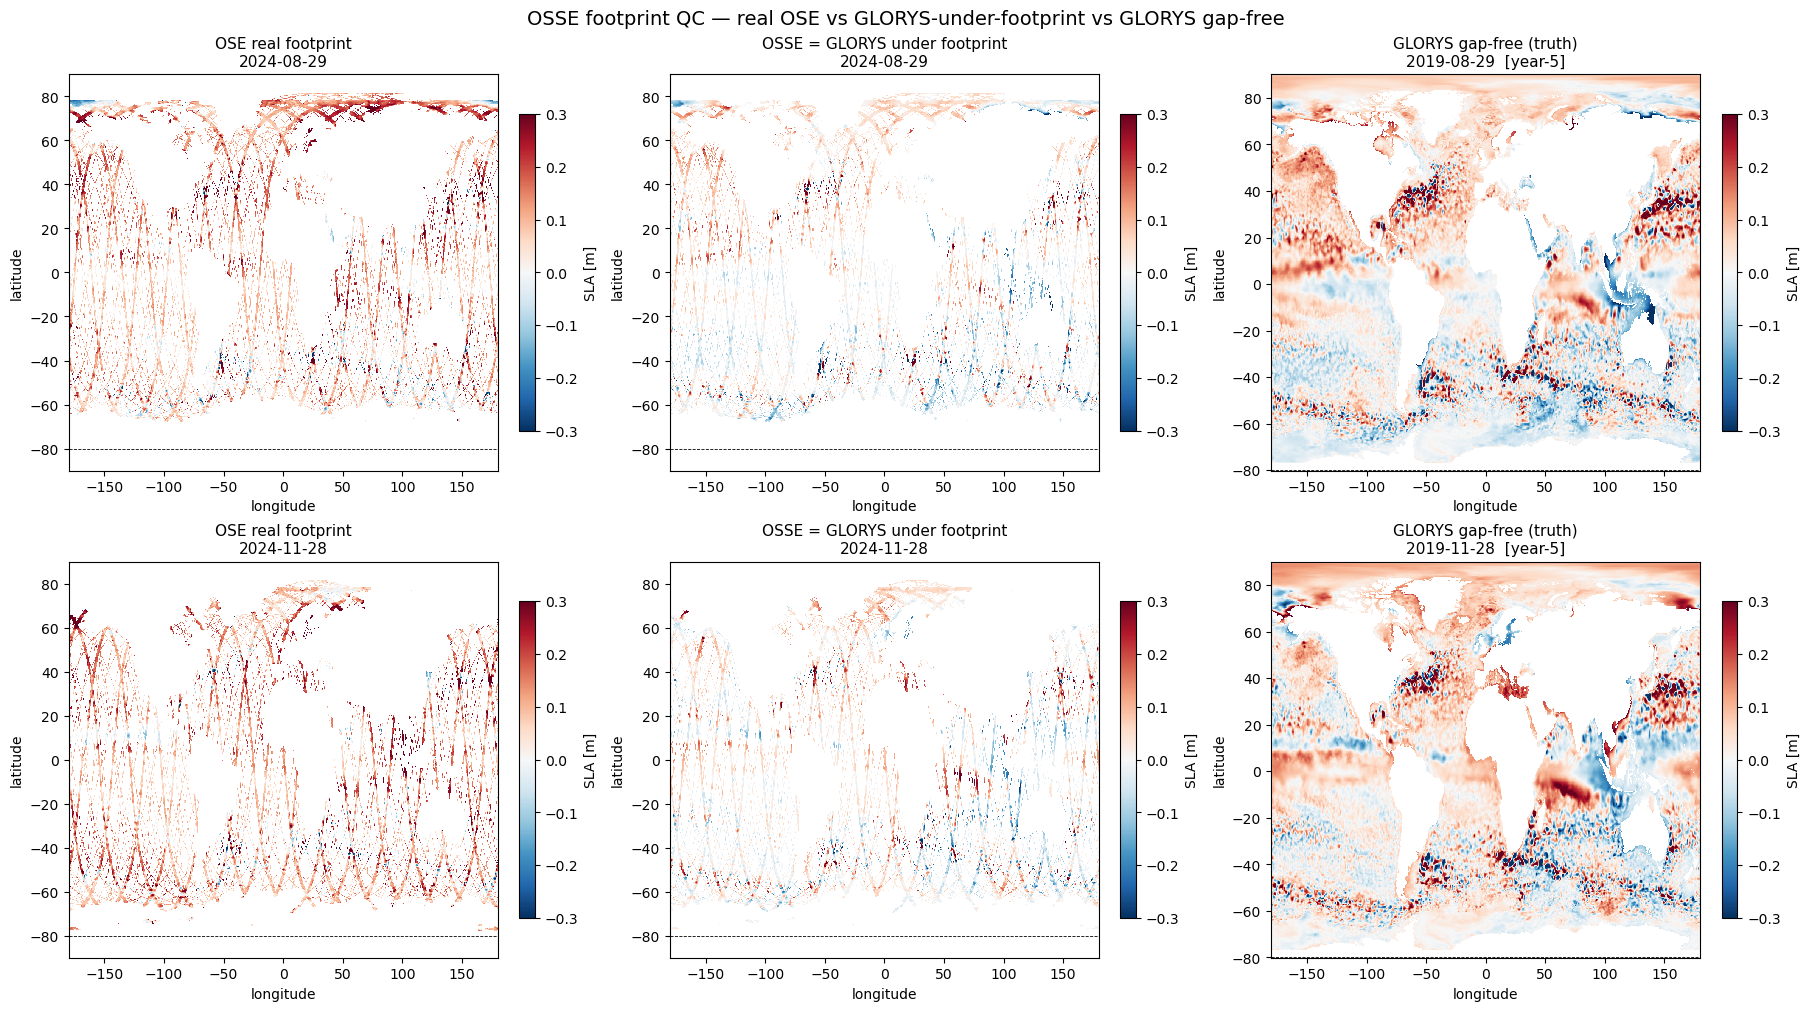

In [8]:
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt

# --- reload everything needed ---
osse_wo = xr.open_dataset(OUT_DIR / 'Glorys12_alongtrack_S7nadirsNswotKarinWithLweRemoved_real_2023-01-01_2025-07-31_wo_Altika.nc')['sla']
foot_real = xr.open_dataset(FOOT_A)['sla']                       # real OSE footprint (source)
gl_full = xr.open_dataset(GLORYS)['sla'].rename({'lat':'latitude','lon':'longitude'})  # GLORYS gap-free

def glorys_twin(day):                                            # 2024-xx -> 2019-xx
    t = pd.Timestamp(day)
    return pd.Timestamp(year=t.year - YEAR_SHIFT, month=t.month, day=t.day)

# --- pick two random days that exist in the OSSE output ---
rng = np.random.default_rng(0)
days = pd.to_datetime(osse_wo.time.values)
picks = pd.to_datetime(rng.choice(days, size=2, replace=False)).sort_values()
print('plotting days:', [str(d.date()) for d in picks])

VMIN, VMAX = -0.3, 0.3
fig, axes = plt.subplots(len(picks), 3, figsize=(18, 5*len(picks)), constrained_layout=True)

for r, day in enumerate(picks):
    twin = glorys_twin(day)
    real = foot_real.sel(time=day)
    osse = osse_wo.sel(time=day)
    full = gl_full.sel(time=twin, method='nearest')

    for c, (da, title) in enumerate([
        (real, f'OSE real footprint\n{day.date()}'),
        (osse, f'OSSE = GLORYS under footprint\n{day.date()}'),
        (full, f'GLORYS gap-free (truth)\n{twin.date()}  [year-{YEAR_SHIFT}]'),
    ]):
        ax = axes[r, c] if len(picks) > 1 else axes[c]
        im = ax.pcolormesh(da.longitude, da.latitude, da, cmap='RdBu_r', vmin=VMIN, vmax=VMAX, shading='auto')
        ax.set_title(title, fontsize=11)
        ax.set_xlabel('longitude'); ax.set_ylabel('latitude')
        ax.axhline(-80, color='k', lw=0.6, ls='--')            # GLORYS southern limit
        fig.colorbar(im, ax=ax, shrink=0.8, label='SLA [m]')

fig.suptitle('OSSE footprint QC — real OSE vs GLORYS-under-footprint vs GLORYS gap-free', fontsize=14)
plt.show()

In [9]:
osse_wo

<xarray.DataArray 'sla' (time: 427, latitude: 720, longitude: 1440)> Size: 2GB
[442713600 values with dtype=float32]
Coordinates:
  * time       (time) datetime64[ns] 3kB 2023-12-01 2023-12-02 ... 2025-01-31
  * latitude   (latitude) float32 3kB -89.88 -89.62 -89.38 ... 89.38 89.62 89.88
  * longitude  (longitude) float32 6kB -179.9 -179.6 -179.4 ... 179.6 179.9